# Demo

Do imports.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from ae483.tools import *
from ae483.mytools import *

Load the saved flight data and compare the pursuer and runner mocap tracks.

In [2]:
# Load both rigid-body tracks from the flight data file.
# The flight script may save them under explicit keys or under `bodies`.
filename = 'mocap_test.json'
with open(filename, 'r') as f:
    flight_data = json.load(f)

pursuer_name = 'marker_deck_30'
runner_name = 'marker_deck_16'
bodies = flight_data.get('bodies', {})
pursuer = flight_data.get('mocap_pursuer', bodies.get(pursuer_name, {}))
runner = flight_data.get('mocap_runner', bodies.get(runner_name, {}))

print(f'Pursuer samples: {len(pursuer.get("time", []))}')
print(f'Runner samples: {len(runner.get("time", []))}')

Pursuer samples: 0
Runner samples: 0


## Overlay both mocap trajectories

Qualisys records both bodies against the same clock and in the same coordinate frame, so their raw positions can be plotted together directly.

In [3]:
def valid_xy(body):
    x = np.asarray(body.get('x', []), dtype=float)
    y = np.asarray(body.get('y', []), dtype=float)
    t = np.asarray(body.get('time', []), dtype=float)
    n = min(len(x), len(y), len(t))
    valid = np.isfinite(x[:n]) & np.isfinite(y[:n]) & np.isfinite(t[:n])
    return t[:n][valid], x[:n][valid], y[:n][valid]

t_pur, x_pur, y_pur = valid_xy(pursuer)
t_run, x_run, y_run = valid_xy(runner)

if not len(x_pur) or not len(x_run):
    print('Both mocap tracks need valid samples. Check use_mocap, body names, and the flight data file.')

Both mocap tracks need valid samples. Check use_mocap, body names, and the flight data file.


Plot both drones in the Qualisys x-y plane.

/tmp/ipykernel_689332/743747279.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


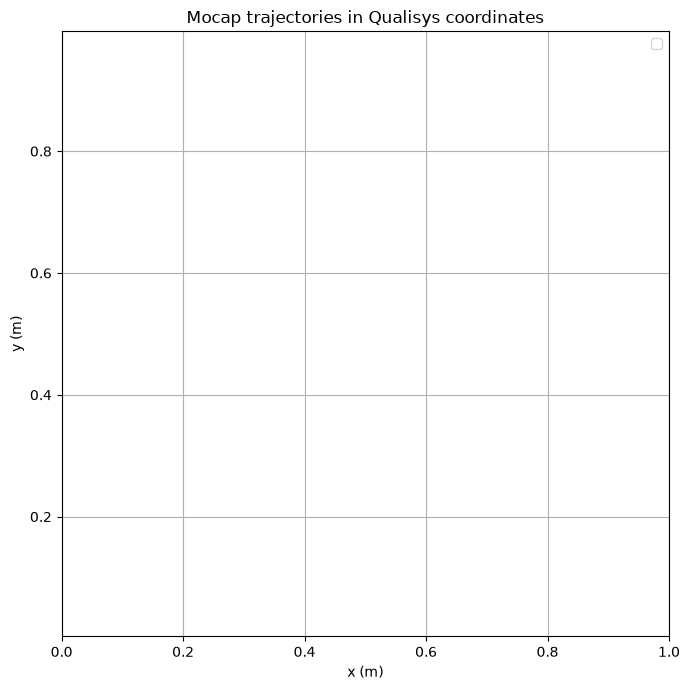

In [4]:
fig, ax = plt.subplots(figsize=(7, 7), tight_layout=True)
if len(x_pur):
    ax.plot(x_pur, y_pur, label=f'pursuer ({pursuer_name})')
    ax.scatter(x_pur[0], y_pur[0], marker='o', s=45, label='pursuer start')
if len(x_run):
    ax.plot(x_run, y_run, '--', label=f'runner ({runner_name})')
    ax.scatter(x_run[0], y_run[0], marker='o', s=45, label='runner start')
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.set_title('Mocap trajectories in Qualisys coordinates')
ax.set_aspect('equal', adjustable='datalim')
ax.grid(True)
ax.legend()
plt.show()

Plot both drones' height over time. Their timestamps come from the same Qualisys stream; invalid samples are omitted.

/tmp/ipykernel_689332/4163291629.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


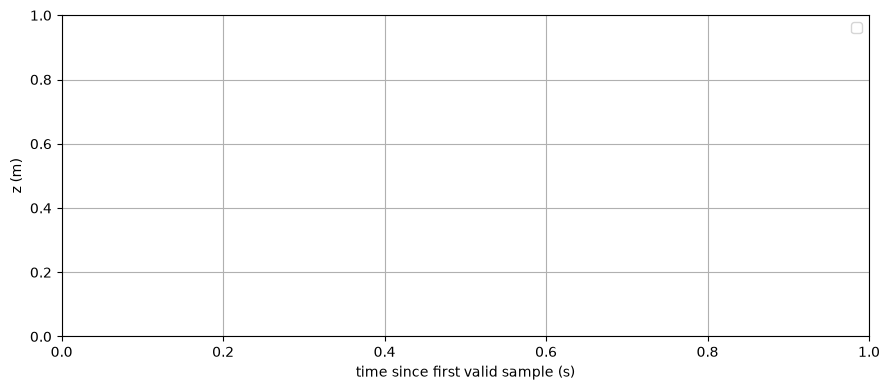

In [5]:
fig, ax = plt.subplots(figsize=(9, 4), tight_layout=True)
for body, label, style in [(pursuer, f'pursuer ({pursuer_name})', '-'), (runner, f'runner ({runner_name})', '--')]:
    time_s = np.asarray(body.get('time', []), dtype=float)
    z = np.asarray(body.get('z', []), dtype=float)
    n = min(len(time_s), len(z))
    valid = np.isfinite(time_s[:n]) & np.isfinite(z[:n])
    if np.any(valid):
        time_valid = time_s[:n][valid]
        ax.plot(time_valid - time_valid[0], z[:n][valid], style, label=label)
ax.set_xlabel('time since first valid sample (s)')
ax.set_ylabel('z (m)')
ax.grid(True)
ax.legend()
plt.show()